# Introdução aos Sistemas Multiagentes: da IA generativa à colaboração entre agentes


1. **Agente único:** um único prompt para as duas tarefas.
2. **Multi agente puro:** dois agentes especializados conectados diretamente em Python.
3. **Multi agente com LangGraph:** os mesmos agentes como nós de um grafo.
4. **LangGraph com Arestas condicionais:** avaliação, aprovação e revisão com limite de tentativas.

Para simplificação, o modelo é **compartilhado** entre todos os agentes. Os arquivos `helpers/` estão fora do notebook e precisam ser carregados para que ele funcione.

## Ambientes de execução do Colab

O Colab permite executar códigos Python, R ou Julia diretamente no navegador, sem precisar instalar ferramentas no computador. Ele oferece diferentes ambientes de execução, utilizando CPU (processador) ou GPU (placa de vídeo).

Embora seja possível executar modelos de linguagem utilizando apenas a CPU, a geração de texto pode ser bastante lenta. Isso acontece porque esses modelos realizam uma grande quantidade de operações matemáticas, que podem ser processadas de forma muito mais eficiente por GPUs, graças à sua capacidade de processamento paralelo.

Neste minicurso, utilizaremos se estiver disponível a GPU NVIDIA T4, que possui 15 GB de memória de vídeo (VRAM) e permite executar modelos de linguagem com maior velocidade.

## Importante: ordem de execução das células

Um Jupyter Notebook é organizado em células, que podem conter textos explicativos ou códigos Python. Para executar uma célula, clique no botão ▶ à esquerda ou pressione `Shift + Enter`.

Execute as células de código na ordem em que aparecem, de cima para baixo! Algumas células dependem de variáveis, funções ou bibliotecas definidas anteriormente. Executá-las fora de ordem pode causar erros.

Se o ambiente for reiniciado ou desconectado, será necessário executar novamente as células anteriores, pois as informações armazenadas na memória são perdidas.

## Preparação: instalar dependências e verificar os arquivos

Envie a pasta `helpers` do ZIP ao diretório `/helpers` (preservando sua estrutura) antes de executar. Como o Colab não envia pastas diretamente com facilidade, é mais simples enviar o ZIP completo, descompactá-lo pelo painel de arquivos do Colab e abrir o notebook na mesma pasta do projeto. Também é possível montar o Google Drive e ajustar o diretório de trabalho.

As célula seguintes **apenas verificam** se os arquivos estão disponíveis e instalam as dependências. Elas não criarão o pacote.

In [1]:
%pip -q install transformers langgraph accelerate sentencepiece graphviz

In [4]:
from pathlib import Path
import os
import sys
import importlib

# Colab geralmente inicia em /content. Ajuste somente se o projeto estiver em outro diretório.
PROJETO = Path.cwd()
if not (PROJETO / "helpers").is_dir() and (PROJETO / "minicurso_multiagentes" / "helpers").is_dir():
    PROJETO = PROJETO / "minicurso_multiagentes"

esperados = ["__init__.py", "inference.py", "reports.py", "content.py", "visualize.py"]
faltantes = [nome for nome in esperados if not (PROJETO / "helpers" / nome).is_file()]
if faltantes:
    raise FileNotFoundError(
        f"Pacote helpers incompleto em {PROJETO / 'helpers'}. "
        f"Arquivos ausentes: {faltantes}. "
        "Extraia o ZIP do projeto mantendo a pasta helpers e ajuste PROJETO se necessário."
    )

os.chdir(PROJETO)

# Se o módulo helpers já foi importado antes, força o recarregamento para aplicar as mudanças do __init__.py
if "helpers" in sys.modules:
    importlib.reload(sys.modules["helpers"])

from helpers import (
    carregar_modelo, consultar_llm, mostrar_resultado, tabela_comparativa, visualizar_grafo, estatisticas_do_agente,
    PROMPT_TRADUTOR, PROMPT_SIMPLIFICADOR, PROMPT_AGENTE_UNICO, PROMPT_AVALIADOR, TEXTOS_TESTE,
)
print("Pacote helpers encontrado e carregado com sucesso:", (PROJETO / "helpers").resolve())
print("Arquivos verificados:", ", ".join(esperados))

Pacote helpers encontrado e carregado com sucesso: /content/helpers
Arquivos verificados: __init__.py, inference.py, reports.py, content.py, visualize.py


**Organização:** todos os arquivos de `helpers` já devem existir antes da aula. As células do notebook apenas importam o pacote, sem criá-lo ou alterá-lo. A função `visualizar_grafo` fica em `helpers/visualize.py`.

## Modelo e dados compartilhados

Os três exercícios devem utilizar **o mesmo modelo e texto** para facilitar a comparação. GPU acelera a execução, mas pode não estar disponível no Colab gratuito. O tempo da primeira inferência também pode incluir inicializações adicionais.

Explicar conceito de SLM e quais outros modelos rodam aqui

In [5]:
MODEL_ID = "LiquidAI/LFM2.5-1.2B-Instruct"
# MODEL_ID = "Qwen/Qwen3-0.6B"

model, tokenizer, DEVICE = carregar_modelo(MODEL_ID)
print("Modelo:", MODEL_ID, "| Dispositivo:", DEVICE)

def perguntar(system_prompt: str, user_prompt: str, max_new_tokens: int = 420) -> dict:
    """Interface simplificada do modelo (infraestrutura em helpers.inference)."""
    return consultar_llm(model, tokenizer, DEVICE, system_prompt, user_prompt, max_new_tokens)

# TEXTO_ORIGINAL = TEXTOS_TESTE["redes_curto"]  # rápido para a primeira execução
TEXTO_ORIGINAL = TEXTOS_TESTE["redes"]       # mais longo e desafiador
print("Texto de entrada:\n", TEXTO_ORIGINAL)

config.json:   0%|          | 0.00/1.22k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/92.2k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/4.73M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/434 [00:00<?, ?B/s]

chat_template.jinja:   0%|          | 0.00/5.49k [00:00<?, ?B/s]

...

model.safetensors: reconstructing file:   0%|          |  0.00B / 2.34GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/132 [00:00<?, ?B/s]

Modelo: LiquidAI/LFM2.5-1.2B-Instruct | Dispositivo: cuda
Texto de entrada:
 Modern computer networks rely on multiple interconnected devices and communication protocols to ensure that information can be transmitted efficiently and securely. When a user accesses a website, their device typically sends a request to a Domain Name System (DNS) server, which translates the website's domain name into an IP address. This process allows the device to identify the destination server without requiring the user to remember numerical addresses. Once the destination has been identified, data is divided into smaller units called packets, which may travel through different routes before reaching the server. Routers determine where these packets should be forwarded, while switches facilitate communication between devices within the same local network. However, network performance can be affected by congestion, hardware failures, or incorrect configurations. For example, if several devices attempt to 

# Parte 1: Agente único

Um único agente deve **traduzir e simplificar na mesma chamada**. O prompt tenta combinar duas tarefas diferentes, o que pode resultar em tradução incompleta, omissões ou simplificação fraca. A falha, se ocorrer, é material para discussão.

In [6]:
def agente_unico(texto_em_ingles: str) -> dict:
    return perguntar(PROMPT_AGENTE_UNICO, f"Texto em inglês:\n{texto_em_ingles}")

resposta_unica = agente_unico(TEXTO_ORIGINAL)
resultado_unico = {
    "original": TEXTO_ORIGINAL,
    "simplificacao": resposta_unica["texto"],
    "estatisticas": [estatisticas_do_agente("único", resposta_unica)],
}
mostrar_resultado(resultado_unico)

[transformers] `causal_conv1d_fn` is falling back to its reference PyTorch implementation because `causal_conv1d` is not installed. This is correct but much slower; install `causal_conv1d` for the optimized kernel.
[transformers] `causal_conv1d_update` is falling back to its reference PyTorch implementation because `causal_conv1d` is not installed. This is correct but much slower; install `causal_conv1d` for the optimized kernel.


**Discussão:** o trabalho foi feito? A tradução foi completa? O texto está mais simples? O modelo inventou ou omitiu informações? O resultado da tradução pode ser validado separadamente? E se  a tradução não acontecer e devolver o texto em inglês, o que acontece com o processo de simplificação?

# Parte 2: Multi agente

Agora dividimos o trabalho em dois agentes com **prompts especializados**:

- O **tradutor** recebe o inglês e devolve português sem simplificar.
- O **simplificador** recebe **somente a tradução** e a reescreve em linguagem acessível.

A orquestração é uma função Python comum. Nenhum framework de agentes é necessário.

In [8]:
def agente_tradutor(texto_em_ingles: str) -> dict:
    return perguntar(PROMPT_TRADUTOR, f"Texto a traduzir:\n{texto_em_ingles}")


def agente_simplificador(texto_em_portugues: str) -> dict:
    return perguntar(PROMPT_SIMPLIFICADOR, f"Texto a simplificar:\n{texto_em_portugues}")

In [9]:
def executar_manualmente(texto_original: str) -> dict:
    traducao = agente_tradutor(texto_original)
    print("Etapa 1 — Tradução:\n", traducao["texto"])

    simplificacao = agente_simplificador(traducao["texto"])
    print("\nEtapa 2 — Simplificação:\n", simplificacao["texto"])

    return {
        "original": texto_original,
        "traducao": traducao["texto"],
        "simplificacao": simplificacao["texto"],
        "estatisticas": [
            estatisticas_do_agente("tradutor", traducao),
            estatisticas_do_agente("simplificador", simplificacao),
        ],
    }

resultado_manual = executar_manualmente(TEXTO_ORIGINAL)
mostrar_resultado(resultado_manual)

Etapa 1 — Tradução:
 Rede de computadores modernos depende de dispositivos interconectados e protocolos de comunicação para garantir que as informações sejam transmitidas de forma eficiente e segura. Quando um usuário acessa um site, seu dispositivo geralmente envia uma solicitação a um servidor de Sistema de Nomes de Domínio (DNS), que traduz o nome de domínio do site em um endereço IP. Esse processo permite que o dispositivo identifique o servidor de destino sem que o usuário precise lembrar endereços numéricos. Após a identificação do destino, os dados são divididos em unidades menores chamadas pacotes, que podem percorrer diferentes rotas antes de chegar ao servidor. Routers decidem onde os pacotes devem ser encaminhados, enquanto switches facilitam a comunicação entre dispositivos dentro da mesma rede local. No entanto, o desempenho da rede pode ser impactado por congestionamentos, falhas de hardware ou configurações incorretas. Por exemplo, se vários dispositivos tentarem transmi

**Discussão:** qual foi a responsabilidade de cada agente? O resultado intermediário pode ser validado? E se o tradutor devolver o texto em inglês, o que ocorrerá com o simplificador?

# Parte 3: Multi agente com LangGraph

Vamos reaproveitar **as mesmas funções e prompts da Parte 2**. Agora a orquestração será descrita por um **grafo de estados**. Cada nó recebe o **estado atual** e retorna apenas os campos que **deseja atualizar**.

In [ ]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END

class EstadoTexto(TypedDict, total=False):
    original: str
    traducao: str
    simplificacao: str
    estatisticas: list[dict]


def no_tradutor(estado: EstadoTexto) -> dict:
    resposta = agente_tradutor(estado["original"])
    return {
        "traducao": resposta["texto"],
        "estatisticas": estado.get("estatisticas", []) + [estatisticas_do_agente("tradutor", resposta)],
    }


def no_simplificador(estado: EstadoTexto) -> dict:
    resposta = agente_simplificador(estado["traducao"])
    return {
        "simplificacao": resposta["texto"],
        "estatisticas": estado.get("estatisticas", []) + [estatisticas_do_agente("simplificador", resposta)],
    }

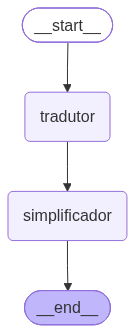

In [ ]:
construtor = StateGraph(EstadoTexto)
construtor.add_node("tradutor", no_tradutor)
construtor.add_node("simplificador", no_simplificador)
construtor.add_edge(START, "tradutor")
construtor.add_edge("tradutor", "simplificador")
construtor.add_edge("simplificador", END)

grafo = construtor.compile()
visualizar_grafo(grafo)

In [ ]:
resultado_grafo = grafo.invoke({"original": TEXTO_ORIGINAL, "estatisticas": []})
mostrar_resultado(resultado_grafo)

## Comparação

Compare o texto, o número de chamadas, tokens de entrada/saída e o tempo. **Resultados diferentes entre Python puro e LangGraph não significam que o LangGraph melhorou ou piorou a qualidade:** ambos invocam os mesmos agentes, e a geração pode variar.

In [ ]:
display(tabela_comparativa({
    "Single agent": resultado_unico,
    "Multi agent (Python)": resultado_manual,
    "Multi agent (LangGraph)": resultado_grafo,
}))

,Arquitetura,Chamadas,Tokens entrada,Tokens saída,Tempo geração (s),Texto final
0,Single agent,1,345,141,5.80,Modern computer networks use many connected de...
1,Multi agent (Python),2,1081,573,11.88,Rede de computadores usa dispositivos conectad...
2,Multi agent (LangGraph),2,1081,573,11.16,Rede de computadores usa dispositivos conectad...


# Parte 4: Arestas condicionais — avaliador e revisão

Agora acrescentamos um **terceiro agente**, o **avaliador**, que compara a tradução com a simplificação e responde em um formato simples:

- `Aprovado.` — encerra a execução;
- `Reprovado. <justificativa>` — volta ao simplificador, que recebe o feedback e tenta corrigir o texto.

Esta parte usa **um novo tipo de estado** e **um novo grafo**; o grafo da Parte 3 continua inalterado. Para evitar ciclos infinitos e custos excessivos, permitimos **no máximo duas revisões**. O feedback do avaliador é uma sugestão do modelo, não uma garantia de correção.

In [ ]:
# Um novo estado, específico para o fluxo com revisão
class EstadoTextoAvaliado(TypedDict, total=False):
    original: str
    traducao: str
    simplificacao: str
    avaliacao: str
    aprovado: bool
    justificativa: str
    revisoes: int
    max_revisoes: int
    historico_avaliacoes: list[str]
    estatisticas: list[dict]


def no_tradutor_avaliado(estado: EstadoTextoAvaliado) -> dict:
    resposta = agente_tradutor(estado["original"])
    return {
        "traducao": resposta["texto"],
        "estatisticas": estado.get("estatisticas", []) + [
            estatisticas_do_agente("tradutor", resposta)
        ],
    }


def no_simplificador_avaliado(estado: EstadoTextoAvaliado) -> dict:
    # A primeira execução não recebe feedback; as seguintes recebem a justificativa.
    entrada = f"Texto a simplificar:\n{estado['traducao']}"
    if estado.get("justificativa"):
        entrada += (
            f"\n\nVersão anterior:\n{estado['simplificacao']}"
            f"\n\nProblema apontado pelo avaliador:\n{estado['justificativa']}"
            "\nRevise a versão anterior para corrigir esse problema. "
            "Preserve o significado do texto traduzido e responda apenas com o texto revisado."
        )

    resposta = perguntar(PROMPT_SIMPLIFICADOR, entrada)
    nova_revisao = estado.get("revisoes", 0) + (1 if estado.get("justificativa") else 0)
    print(f"Simplificador: versão {nova_revisao + 1}")
    return {
        "simplificacao": resposta["texto"],
        "revisoes": nova_revisao,
        "estatisticas": estado.get("estatisticas", []) + [
            estatisticas_do_agente("simplificador", resposta)
        ],
    }

In [ ]:
def agente_avaliador(traducao: str, simplificacao: str) -> dict:
    entrada = (
        f"Texto traduzido:\n{traducao}\n\n"
        f"Texto simplificado:\n{simplificacao}"
    )
    return perguntar(PROMPT_AVALIADOR, entrada, max_new_tokens=120)


def no_avaliador(estado: EstadoTextoAvaliado) -> dict:
    resposta = agente_avaliador(estado["traducao"], estado["simplificacao"])
    texto = resposta["texto"].strip()

    # Não confiar em texto livre como sinal de controle: analisar o prefixo.
    if texto.startswith("Aprovado."):
        aprovado = True
        justificativa = ""
    elif texto.startswith("Reprovado."):
        aprovado = False
        justificativa = texto[len("Reprovado."):].strip() or "Revisar clareza e fidelidade ao original."
    else:
        aprovado = False
        justificativa = (
            "O avaliador não seguiu o formato solicitado; "
            f"resposta recebida: {texto[:160]!r}"
        )

    print(f"Avaliador: {texto}")
    return {
        "avaliacao": texto,
        "aprovado": aprovado,
        "justificativa": justificativa,
        "historico_avaliacoes": estado.get("historico_avaliacoes", []) + [texto],
        "estatisticas": estado.get("estatisticas", []) + [
            estatisticas_do_agente("avaliador", resposta)
        ],
    }


def decidir_apos_avaliacao(estado: EstadoTextoAvaliado) -> str:
    if estado["aprovado"]:
        return "fim"
    if estado.get("revisoes", 0) >= estado.get("max_revisoes", 2):
        return "fim"
    return "revisar"

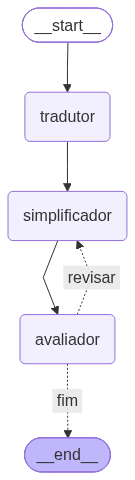

In [ ]:
# Novo grafo: o da Parte 3 permanece disponível em `grafo`.
construtor_avaliado = StateGraph(EstadoTextoAvaliado)
construtor_avaliado.add_node("tradutor", no_tradutor_avaliado)
construtor_avaliado.add_node("simplificador", no_simplificador_avaliado)
construtor_avaliado.add_node("avaliador", no_avaliador)

construtor_avaliado.add_edge(START, "tradutor")
construtor_avaliado.add_edge("tradutor", "simplificador")
construtor_avaliado.add_edge("simplificador", "avaliador")
construtor_avaliado.add_conditional_edges(
    "avaliador",
    decidir_apos_avaliacao,
    {"revisar": "simplificador", "fim": END},
)

grafo_avaliado = construtor_avaliado.compile()
visualizar_grafo(grafo_avaliado)

In [ ]:
resultado_avaliado = grafo_avaliado.invoke(
    {
        "original": TEXTO_ORIGINAL,
        "revisoes": 0,
        "max_revisoes": 2,
        "estatisticas": [],
        "historico_avaliacoes": [],
    },
    config={"recursion_limit": 15},
)

mostrar_resultado(resultado_avaliado)
print("\nAvaliações:")
for indice, avaliacao in enumerate(resultado_avaliado["historico_avaliacoes"], 1):
    print(f"{indice}. {avaliacao}")
print("Revisões realizadas:", resultado_avaliado["revisoes"])
print("Aprovado:", resultado_avaliado["aprovado"])
if not resultado_avaliado["aprovado"]:
    print("O sistema encerrou sem aprovação (limite de revisões ou resposta inválida).")

Simplificador: versão 1
Avaliador: Aprovado.  
A versão simplificada preserva as informações essenciais sobre como a rede funciona, sem inventar fatos ou complicar o conteúdo para leitores não especialistas.



Avaliações:
1. Aprovado.  
A versão simplificada preserva as informações essenciais sobre como a rede funciona, sem inventar fatos ou complicar o conteúdo para leitores não especialistas.
Revisões realizadas: 0
Aprovado: True


**Discussão:** quando o avaliador reprova, o que muda no estado? Por que existe uma aresta de retorno? O sistema sempre melhora após uma revisão? Como o número máximo de revisões evita um loop infinito? Compare também o número de chamadas e tokens com as três abordagens anteriores.

## Comparação Final

Agora que implementamos as quatro abordagens, podemos comparar os textos produzidos, a quantidade de chamadas ao modelo, os tokens de entrada e saída e o tempo de execução.

Observe como a arquitetura evoluiu: começamos com um único agente, dividimos a tarefa entre agentes especializados, organizamos sua execução com LangGraph e, por fim, adicionamos um agente avaliador capaz de solicitar revisões por meio de arestas condicionais.

Porém, **uma arquitetura mais complexa não garante resultados melhores.** Diferenças entre as saídas podem ocorrer devido à variabilidade do modelo, enquanto o uso de agentes adicionais e ciclos de revisão aumenta o custo computacional e possívelmente financeiro.

O objetivo é observar como cada abordagem organiza as tarefas e discutir se a especialização e a avaliação contribuem para a qualidade dos resultados.

In [ ]:
display(tabela_comparativa({
    "Agente único": resultado_unico,
    "Multi agente (Python)": resultado_manual,
    "Multi agente (LangGraph)": resultado_grafo,
    "Multi agente (LangGraph + avaliação)": resultado_avaliado,
}))

,Arquitetura,Chamadas,Tokens entrada,Tokens saída,Tempo geração (s),Texto final
0,Agente único,1,345,141,5.80,Modern computer networks use many connected de...
1,Multi agente (Python),2,1081,573,11.88,Rede de computadores usa dispositivos conectad...
2,Multi agente (LangGraph),2,1081,573,11.16,Rede de computadores usa dispositivos conectad...
3,Multi agente (LangGraph + avaliação),3,1819,619,12.00,Rede de computadores usa dispositivos conectad...


## Exercício opcional

Troque `TEXTO_ORIGINAL` por `TEXTOS_TESTE["computacao_nuvem"]` ou `TEXTOS_TESTE["redes"]`, execute as três partes novamente e discuta as diferenças. Para conhecer outro modelo, altere `MODEL_ID` e reinicie a execução desde o carregamento.

**Perguntas:** os agentes realmente se especializaram? Qual configuração consumiu mais tokens? Vale a pena separar as tarefas? Como adicionar um terceiro agente revisor?